# **Conformal prediction for regression**

###### group member: Kelly HILLAH, Chaima EL HADAD, Mariam ABDILLAHI AHMED & Ouiam EL GHALBZOURI

**Research Question:** Given a community’s socio-economic, demographic and housing characteristics, how well can we predict its per-capita violent crime rate, and how reliable are the prediction intervals around those predictions?

In [ ]:
import os # interfacing with the operating system
import matplotlib.pyplot as plt # vizualization
import numpy as np # scientific computing and linear algebra
import pandas as pd # create and handling DataFrames
import sklearn.linear_model # contains a set of methods for linear models
from sklearn.metrics import r2_score # compute R2 (see previous tutorial)
from sklearn.metrics import mean_squared_error # compute mean squared error
from sklearn.metrics import mean_absolute_error # compute mean absolute error

In [ ]:
pip install ucimlrepo

In [ ]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
communities_and_crime = fetch_ucirepo(id=183)

# data (as pandas dataframes)
X = communities_and_crime.data.features
y = communities_and_crime.data.targets

# metadata
print(communities_and_crime.metadata)

# variable information
print(communities_and_crime.variables)


{'uci_id': 183, 'name': 'Communities and Crime', 'repository_url': 'https://archive.ics.uci.edu/dataset/183/communities+and+crime', 'data_url': 'https://archive.ics.uci.edu/static/public/183/data.csv', 'abstract': 'Communities within the United States. The data combines socio-economic data from the 1990 US Census, law enforcement data from the 1990 US LEMAS survey, and crime data from the 1995 FBI UCR.', 'area': 'Social Science', 'tasks': ['Regression'], 'characteristics': ['Multivariate'], 'num_instances': 1994, 'num_features': 127, 'feature_types': ['Real'], 'demographics': ['Race', 'Age', 'Income', 'Occupation'], 'target_col': ['ViolentCrimesPerPop'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 2002, 'last_updated': 'Mon Mar 04 2024', 'dataset_doi': '10.24432/C53W3X', 'creators': ['Michael Redmond'], 'intro_paper': {'ID': 405, 'type': 'NATIVE', 'title': 'A data-driven software tool for enabling cooperative information s

In [ ]:
df = pd.concat([X, y], axis=1)

# Afficher les premières lignes avec toutes les variables
print(df.head().to_string())

# Afficher toutes les variables
print(df.columns.tolist())

   state county community        communityname  fold  population  householdsize  racepctblack  racePctWhite  racePctAsian  racePctHisp  agePct12t21  agePct12t29  agePct16t24  agePct65up  numbUrban  pctUrban  medIncome  pctWWage  pctWFarmSelf  pctWInvInc  pctWSocSec  pctWPubAsst  pctWRetire  medFamInc  perCapInc  whitePerCap  blackPerCap  indianPerCap  AsianPerCap OtherPerCap  HispPerCap  NumUnderPov  PctPopUnderPov  PctLess9thGrade  PctNotHSGrad  PctBSorMore  PctUnemployed  PctEmploy  PctEmplManu  PctEmplProfServ  PctOccupManu  PctOccupMgmtProf  MalePctDivorce  MalePctNevMarr  FemalePctDiv  TotalPctDiv  PersPerFam  PctFam2Par  PctKids2Par  PctYoungKids2Par  PctTeen2Par  PctWorkMomYoungKids  PctWorkMom  NumIlleg  PctIlleg  NumImmig  PctImmigRecent  PctImmigRec5  PctImmigRec8  PctImmigRec10  PctRecentImmig  PctRecImmig5  PctRecImmig8  PctRecImmig10  PctSpeakEnglOnly  PctNotSpeakEnglWell  PctLargHouseFam  PctLargHouseOccup  PersPerOccupHous  PersPerOwnOccHous  PersPerRentOccHous  PctPersO

# Preprocessing

In [ ]:
print(df.shape)

(1994, 128)


In [ ]:
missing = (df == '?').sum()
print(missing[missing > 0].sort_values(ascending=False))

LemasSwFTPerPop         1675
LemasTotalReq           1675
LemasSwornFT            1675
LemasSwFTFieldPerPop    1675
LemasSwFTFieldOps       1675
LemasTotReqPerPop       1675
RacialMatchCommPol      1675
PolicPerPop             1675
PolicReqPerOffic        1675
OfficAssgnDrugUnits     1675
NumKindsDrugsSeiz       1675
PolicAveOTWorked        1675
PctPolicWhite           1675
PctPolicBlack           1675
PctPolicHisp            1675
PctPolicAsian           1675
PctPolicMinor           1675
PolicOperBudg           1675
LemasPctPolicOnPatr     1675
LemasGangUnitDeploy     1675
PolicCars               1675
PolicBudgPerPop         1675
community               1177
county                  1174
OtherPerCap                1
dtype: int64


In [ ]:
# Colonnes à supprimer
cols_to_drop = [
    'LemasSwFTPerPop',
    'LemasTotalReq',
    'LemasSwornFT',
    'LemasSwFTFieldPerPop',
    'LemasSwFTFieldOps',
    'LemasTotReqPerPop',
    'RacialMatchCommPol',
    'PolicPerPop',
    'PolicReqPerOffic',
    'OfficAssgnDrugUnits',
    'NumKindsDrugsSeiz',
    'PolicAveOTWorked',
    'PctPolicWhite',
    'PctPolicBlack',
    'PctPolicHisp',
    'PctPolicAsian',
    'PctPolicMinor',
    'PolicOperBudg',
    'LemasPctPolicOnPatr',
    'LemasGangUnitDeploy',
    'PolicCars',
    'PolicBudgPerPop',
    'community',
    'county'
]


df = df.drop(columns=cols_to_drop, errors='ignore')


print("Dimensions du dataset :", df.shape)
print(df.head())

Dimensions du dataset : (1994, 104)
   state        communityname  fold  population  householdsize  racepctblack  \
0      8         Lakewoodcity     1        0.19           0.33          0.02   
1     53          Tukwilacity     1        0.00           0.16          0.12   
2     24         Aberdeentown     1        0.00           0.42          0.49   
3     34  Willingborotownship     1        0.04           0.77          1.00   
4     42    Bethlehemtownship     1        0.01           0.55          0.02   

   racePctWhite  racePctAsian  racePctHisp  agePct12t21  ...  PctForeignBorn  \
0          0.90          0.12         0.17         0.34  ...            0.12   
1          0.74          0.45         0.07         0.26  ...            0.21   
2          0.56          0.17         0.04         0.39  ...            0.14   
3          0.08          0.12         0.10         0.51  ...            0.19   
4          0.95          0.09         0.05         0.38  ...            0.11   

  

In [ ]:
data = df[df['OtherPerCap'] != '?'].copy()

print(data.shape)

(1993, 104)


We see that 24 columns present have around 84% of missing values. We decided to drop those variables except `OtherPerCap` since it only has 1 missing value (that we dropped too).

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1993 entries, 0 to 1993
Columns: 104 entries, state to ViolentCrimesPerPop
dtypes: float64(100), int64(2), object(2)
memory usage: 1.6+ MB


In [ ]:
print(data.select_dtypes(include='object').columns.tolist())

['communityname', 'OtherPerCap']


In [ ]:
data['OtherPerCap'] = pd.to_numeric(data['OtherPerCap'], errors='coerce')

print(data['OtherPerCap'].dtype)

float64


Let's look at the duplicates

In [ ]:
# 1. Compter les doublons
print("Nombre de doublons :", data.duplicated().sum())

# 2. Afficher les lignes dupliquées
print(data[data.duplicated()])

# 3. Supprimer les doublons
data = data.drop_duplicates().copy()

# 4. Vérifier le résultat
print("Doublons restants :", data.duplicated().sum())
print("Dimensions finales :", data.shape)

Nombre de doublons : 0
Empty DataFrame
Columns: [state, communityname, fold, population, householdsize, racepctblack, racePctWhite, racePctAsian, racePctHisp, agePct12t21, agePct12t29, agePct16t24, agePct65up, numbUrban, pctUrban, medIncome, pctWWage, pctWFarmSelf, pctWInvInc, pctWSocSec, pctWPubAsst, pctWRetire, medFamInc, perCapInc, whitePerCap, blackPerCap, indianPerCap, AsianPerCap, OtherPerCap, HispPerCap, NumUnderPov, PctPopUnderPov, PctLess9thGrade, PctNotHSGrad, PctBSorMore, PctUnemployed, PctEmploy, PctEmplManu, PctEmplProfServ, PctOccupManu, PctOccupMgmtProf, MalePctDivorce, MalePctNevMarr, FemalePctDiv, TotalPctDiv, PersPerFam, PctFam2Par, PctKids2Par, PctYoungKids2Par, PctTeen2Par, PctWorkMomYoungKids, PctWorkMom, NumIlleg, PctIlleg, NumImmig, PctImmigRecent, PctImmigRec5, PctImmigRec8, PctImmigRec10, PctRecentImmig, PctRecImmig5, PctRecImmig8, PctRecImmig10, PctSpeakEnglOnly, PctNotSpeakEnglWell, PctLargHouseFam, PctLargHouseOccup, PersPerOccupHous, PersPerOwnOccHous, Pers

No duplicate


In [ ]:
# Summary statistics
print(data['ViolentCrimesPerPop'].describe())

count    1993.000000
mean        0.237983
std         0.233043
min         0.000000
25%         0.070000
50%         0.150000
75%         0.330000
max         1.000000
Name: ViolentCrimesPerPop, dtype: float64


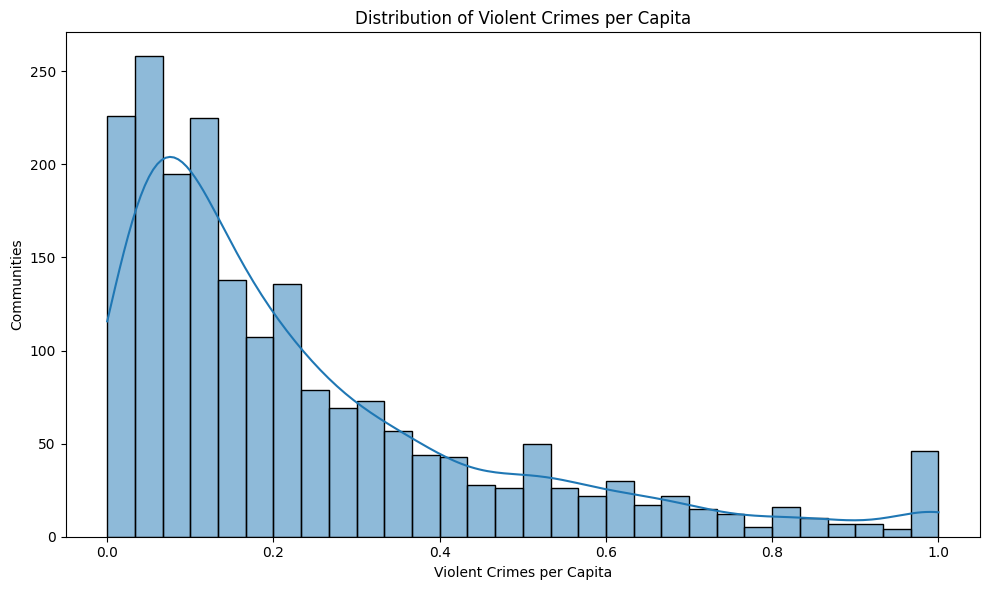

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.histplot(data=data, x='ViolentCrimesPerPop', bins=30, kde=True)

plt.title('Distribution of Violent Crimes per Capita')
plt.xlabel('Violent Crimes per Capita')
plt.ylabel('Communities')

plt.tight_layout()
plt.show()

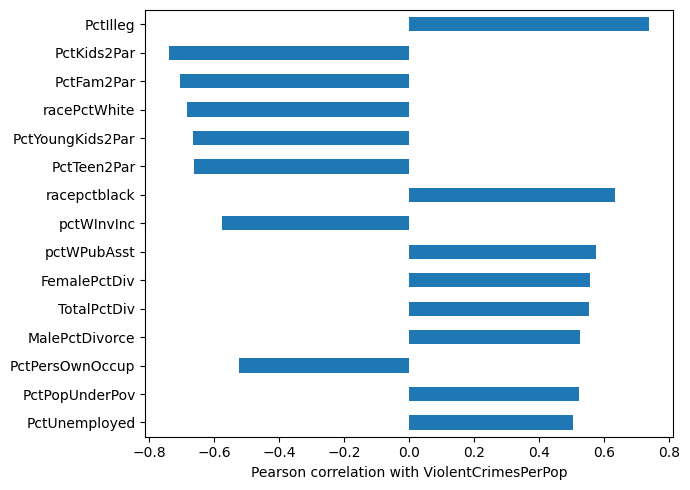

In [ ]:
target = "ViolentCrimesPerPop"
corr_t = data.corr(numeric_only=True)[target].drop(target)
top = corr_t.reindex(corr_t.abs().sort_values(ascending=False).index).head(15)

plt.figure(figsize=(7, 5))
top[::-1].plot.barh()
plt.xlabel("Pearson correlation with ViolentCrimesPerPop")
plt.tight_layout()
plt.show()

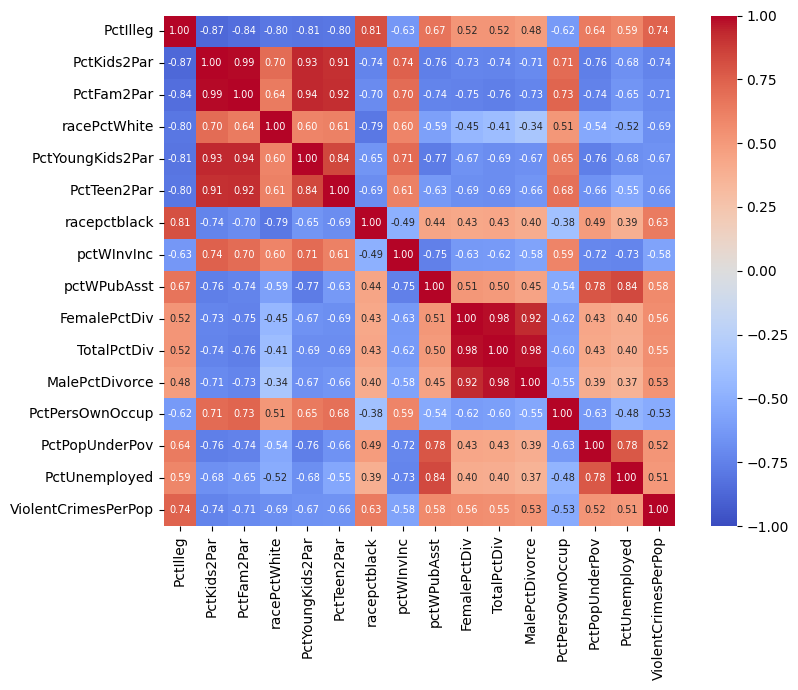

In [ ]:
import seaborn as sns

cols = top.index[:15].tolist() + [target]
plt.figure(figsize=(9, 7))
sns.heatmap(data[cols].corr(), cmap="coolwarm", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 7}, square=True)
plt.tight_layout()
plt.show()

Drop

In [ ]:
data = data.drop(columns=['state', 'communityname', 'fold'], errors='ignore')

print("Dimensions après suppression :", data.shape)
print(data.head())

Dimensions après suppression : (1993, 101)
   population  householdsize  racepctblack  racePctWhite  racePctAsian  \
0        0.19           0.33          0.02          0.90          0.12   
1        0.00           0.16          0.12          0.74          0.45   
2        0.00           0.42          0.49          0.56          0.17   
3        0.04           0.77          1.00          0.08          0.12   
4        0.01           0.55          0.02          0.95          0.09   

   racePctHisp  agePct12t21  agePct12t29  agePct16t24  agePct65up  ...  \
0         0.17         0.34         0.47         0.29        0.32  ...   
1         0.07         0.26         0.59         0.35        0.27  ...   
2         0.04         0.39         0.47         0.28        0.32  ...   
3         0.10         0.51         0.50         0.34        0.21  ...   
4         0.05         0.38         0.38         0.23        0.36  ...   

   PctForeignBorn  PctBornSameState  PctSameHouse85  PctSameCity85 

Extrem value check

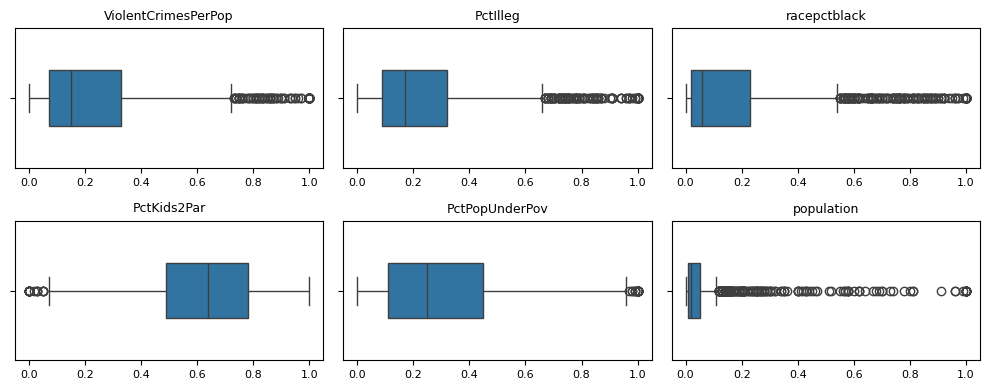

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

cols = [
    'ViolentCrimesPerPop',
    'PctIlleg',
    'racepctblack',
    'PctKids2Par',
    'PctPopUnderPov',
    'population'
]

fig, axes = plt.subplots(2, 3, figsize=(10, 4))
axes = axes.flatten()

for i, col in enumerate(cols):
    sns.boxplot(x=data[col], ax=axes[i], width=0.4)
    axes[i].set_title(col, fontsize=9)
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', labelsize=8)

plt.tight_layout()
plt.show()

# Linear regression

Let's split the dataset

In [ ]:
from sklearn.model_selection import train_test_split

target = "ViolentCrimesPerPop"
X = data.drop(columns=[target])
y = data[target]

# Test set (20%) : on n'y touche plus
X_trval, X_test, y_trval, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# Train (60% total) / calibration (20% total) : la calibration ne sert qu'à la CP, plus tard
X_train, X_calib, y_train, y_calib = train_test_split(X_trval, y_trval, test_size=0.25, random_state=42)

Ici je fait un VIF (Variance Inflation Factor) qui mesure à quel point une variable est redondante avec toutes les autres.

Le Principe : pour chaque variable, on la régresse sur toutes les autres variables explicatives, puis on calcule VIF = 1 / (1 − R²).
- VIF = 1 : la variable est indépendante des autres.
- VIF entre 5 et 10 : colinéarité préoccupante.
-VIF > 10 : colinéarité forte, la variable est quasi une combinaison des autres.

Interprétation : un VIF de 10 signifie que la variance du coefficient est multipliée par 10 à cause de la colinéarité.

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

Xc = X_train.copy()
Xc.insert(0, "const", 1.0)

vif = pd.Series(
    [variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])],
    index=X_train.columns
).sort_values(ascending=False)

print(vif.head(15))

TotalPctDiv          1344.271085
PctPersOwnOccup       592.137355
PctHousOwnOcc         567.915531
OwnOccMedVal          556.183071
PctRecImmig8          436.749571
FemalePctDiv          427.706576
population            383.946795
numbUrban             364.670392
PctRecImmig5          293.440742
PctRecImmig10         292.522786
MalePctDivorce        292.270769
PctLargHouseOccup     237.690475
PctLargHouseFam       232.451909
OwnOccLowQuart        226.333159
PersPerOccupHous      210.369311
dtype: float64


=> Tous ces VIF sont très au-dessus du seuil de 10, certains par un facteur 100. La multicolinéarité est donc forte.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np

lr = LinearRegression().fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

print("RMSE :", np.sqrt(mean_squared_error(y_test, y_pred_lr)))
print("MAE  :", mean_absolute_error(y_test, y_pred_lr))
print("R²   :", r2_score(y_test, y_pred_lr))

RMSE : 0.13889889581878956
MAE  : 0.09563455164569432
R²   : 0.636440893497251


On fait des tests de robustesse pour voir si y'a un intéret a supprimer les variables redondantes.

# REGARDER

In [ ]:
# A PRENDRE EN COMPTE
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import GridSearchCV, KFold, cross_validate
import numpy as np
import pandas as pd

# 1. Outer cross-validation: 5 folds on the training set
cv_outer = KFold(n_splits=5, shuffle=True, random_state=42)

# 2. Define the three models

# OLS
ols = LinearRegression()

# Ridge: alpha selected by inner cross-validation
ridge = make_pipeline(
    StandardScaler(),
    RidgeCV(
        alphas=np.logspace(-3, 3, 30),
        cv=5,
        scoring="neg_root_mean_squared_error"
    )
)

# PCR: number of components selected by inner cross-validation
pcr = GridSearchCV(
    make_pipeline(
        StandardScaler(),
        PCA(),
        LinearRegression()
    ),
    param_grid={
        "pca__n_components": [10, 20, 30, 40, 60, 80]
    },
    cv=5,
    scoring="neg_root_mean_squared_error"
)

models = {
    "OLS": ols,
    "Ridge": ridge,
    "PCR": pcr
}

# 3. Evaluate all models using ONLY the training set
scoring = {
    "RMSE": "neg_root_mean_squared_error",
    "MAE": "neg_mean_absolute_error",
    "R2": "r2"
}

results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv_outer,
        scoring=scoring,
        n_jobs=-1
    )

    results.append({
        "Model": name,
        "RMSE mean": -scores["test_RMSE"].mean(),
        "RMSE std": scores["test_RMSE"].std(),
        "MAE mean": -scores["test_MAE"].mean(),
        "MAE std": scores["test_MAE"].std(),
        "R2 mean": scores["test_R2"].mean(),
        "R2 std": scores["test_R2"].std()
    })

cv_results = pd.DataFrame(results).set_index("Model").round(4)

print("Cross-validation results (training set only):")
print(cv_results)


Cross-validation results (training set only):
       RMSE mean  RMSE std  MAE mean  MAE std  R2 mean  R2 std
Model                                                         
OLS       0.1426    0.0076    0.1019   0.0087   0.6228  0.0714
Ridge     0.1417    0.0053    0.0998   0.0057   0.6300  0.0528
PCR       0.1458    0.0047    0.1035   0.0044   0.6091  0.0514


Le VIF révèle une forte multicolinéarité (groupes divorce, propriété, immigration récente, taille des ménages), ce qui rend les coefficients individuels instables et peu interprétables. Cependant, Ridge et la régression sur composantes principales n’améliorent pas de façon notable la performance prédictive (RMSE de 0.137 et 0.141 contre 0.139 pour la LR), et la validité des intervalles de CP ne dépend pas de cette colinéarité. Nous gardons donc la LR et lisons ses résultats en termes de prédiction plutôt que d’effets individuels des variables.

# Simple Decision Tree

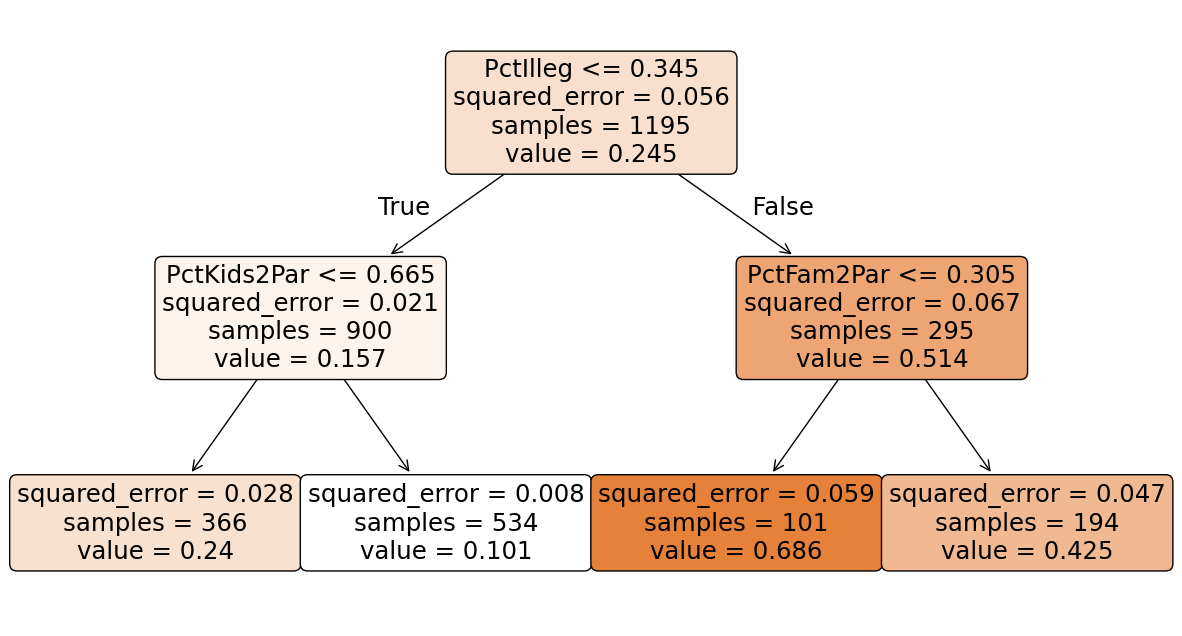

depth 2 - MSE train: 0.0246 - MSE test: 0.0266
depth 3 - MSE train: 0.0208 - MSE test: 0.0252
depth 4 - MSE train: 0.0173 - MSE test: 0.0259
depth 5 - MSE train: 0.0136 - MSE test: 0.0265
depth 6 - MSE train: 0.0097 - MSE test: 0.0314
depth 7 - MSE train: 0.0066 - MSE test: 0.0343
depth 8 - MSE train: 0.004 - MSE test: 0.0362
depth 9 - MSE train: 0.0024 - MSE test: 0.0361
depth 10 - MSE train: 0.0014 - MSE test: 0.0373
depth 11 - MSE train: 0.0007 - MSE test: 0.04
depth 12 - MSE train: 0.0004 - MSE test: 0.0391
depth 13 - MSE train: 0.0002 - MSE test: 0.0359
depth 14 - MSE train: 0.0001 - MSE test: 0.0383
depth 15 - MSE train: 0.0 - MSE test: 0.0359


In [ ]:
from sklearn.tree import DecisionTreeRegressor
from sklearn import tree
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np, pandas as pd, matplotlib.pyplot as plt

# 1) Un petit arbre (profondeur 2), visualisé
tree_reg = DecisionTreeRegressor(max_depth=2, random_state=0)
tree_reg.fit(X_train, y_train)

fig = plt.figure(figsize=(15, 8))
_ = tree.plot_tree(tree_reg, feature_names=X.columns.values, rounded=True, filled=True)
plt.show()

# 2) Effet de la profondeur : erreur train vs validation
for depth in range(2, 16):
    t = DecisionTreeRegressor(max_depth=depth, random_state=0).fit(X_train, y_train)
    mse_train = mean_squared_error(y_train, t.predict(X_train))
    mse_test = mean_squared_error(y_test, t.predict(X_test))
    print("depth", depth, "- MSE train:", round(mse_train, 4), "- MSE test:", round(mse_test, 4))

HERE

In [ ]:
# 3) Tuning par GridSearchCV (comme dans le TP)
param_grid = {'max_depth': range(2, 10),
              'min_samples_split': [2, 4, 6, 8, 10]}

grid_search = GridSearchCV(DecisionTreeRegressor(random_state=0),
                           param_grid,
                           scoring="neg_mean_squared_error",
                           return_train_score=True,
                           cv=3)
grid_search.fit(X_train, y_train)

print(grid_search.best_params_)

# 4) Résultats sur le test
final_model = grid_search.best_estimator_
y_pred_tree = final_model.predict(X_test)

print("RMSE :", np.sqrt(mean_squared_error(y_test, y_pred_tree)))
print("MAE  :", mean_absolute_error(y_test, y_pred_tree))
print("R²   :", r2_score(y_test, y_pred_tree))

{'max_depth': 3, 'min_samples_split': 2}
RMSE : 0.15862977083463714
MAE  : 0.10968340619296357
R²   : 0.5258160670488972


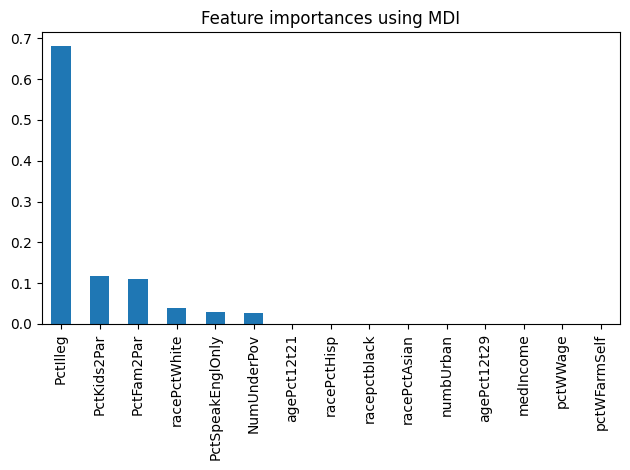

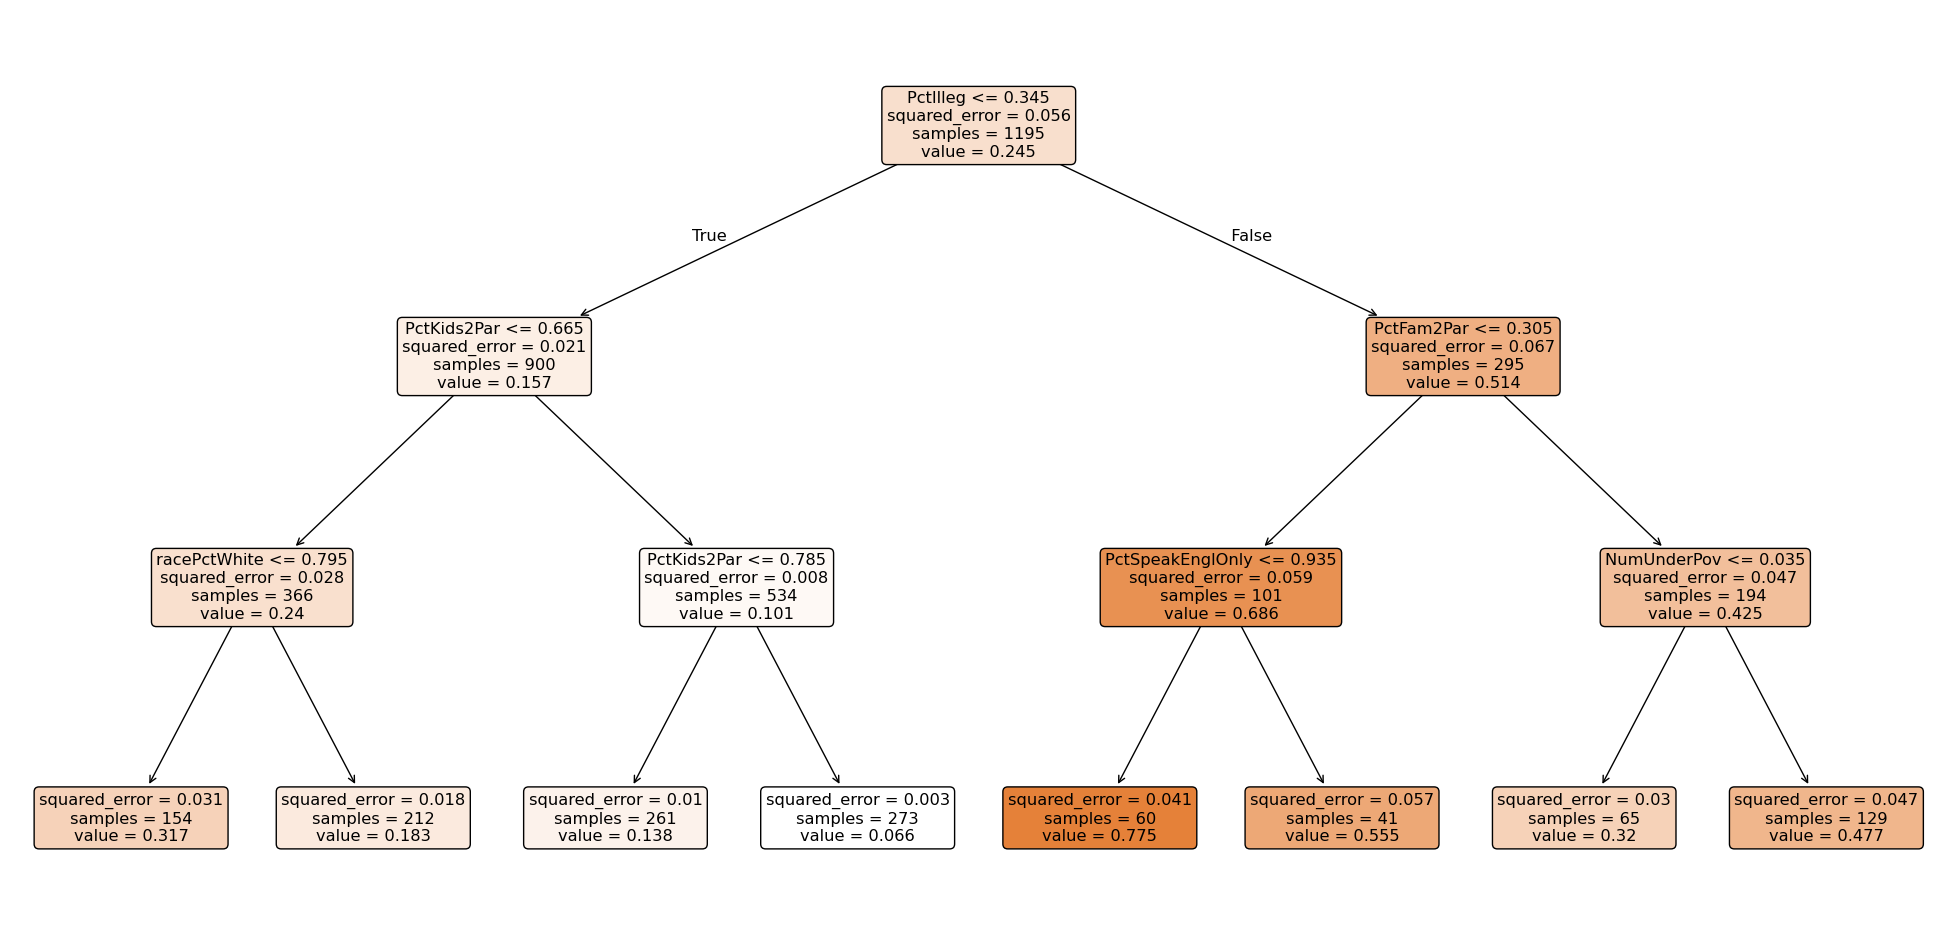

In [ ]:
# 5) Importance des variables (top 15, car tu as ~100 variables)
importance = pd.Series(final_model.feature_importances_, index=X.columns.values)
importance.sort_values(ascending=False).head(15).plot.bar()
plt.title("Feature importances using MDI")
plt.tight_layout()
plt.show()

# 6) Arbre final
fig = plt.figure(figsize=(25, 12))
_ = tree.plot_tree(final_model, feature_names=X.columns.values,
                   rounded=True, filled=True, max_depth=3)
plt.show()

# PAR VALIDATION CROISEE POUR COMPARER LE MEME TYPE DE MODELE

In [ ]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV, KFold, cross_validate

# 1. Outer cross-validation: same folds as OLS
cv_outer = KFold(n_splits=5, shuffle=True, random_state=42)

# 2. Hyperparameter tuning (inner cross-validation)
tree_search = GridSearchCV(
    DecisionTreeRegressor(random_state=0),
    param_grid={
        "max_depth": [2, 3, 4, 5, 6, 8, 10, 12, 15, None],
        "min_samples_split": [2, 5, 10, 20],
        "min_samples_leaf": [1, 2, 5, 10]
    },
    scoring="neg_root_mean_squared_error",
    cv=5
)

# 3. Evaluation metrics
scoring = {
    "RMSE": "neg_root_mean_squared_error",
    "MAE": "neg_mean_absolute_error",
    "R2": "r2"
}

# 4. Nested cross-validation on training set only
tree_scores = cross_validate(
    tree_search,
    X_train,
    y_train,
    cv=cv_outer,
    scoring=scoring,
    n_jobs=-1
)

# 5. Display results
print("Decision Tree - Cross-validation results:")
print("RMSE mean:", round(-tree_scores["test_RMSE"].mean(), 4))
print("RMSE std:", round(tree_scores["test_RMSE"].std(), 4))
print("MAE mean:", round(-tree_scores["test_MAE"].mean(), 4))
print("MAE std:", round(tree_scores["test_MAE"].std(), 4))
print("R2 mean:", round(tree_scores["test_R2"].mean(), 4))
print("R2 std:", round(tree_scores["test_R2"].std(), 4))


Decision Tree - Cross-validation results:
RMSE mean: 0.1626
RMSE std: 0.0048
MAE mean: 0.1137
MAE std: 0.0028
R2 mean: 0.5152
R2 std: 0.0445


Best parameters: {'max_depth': 4, 'min_samples_leaf': 10, 'min_samples_split': 2}


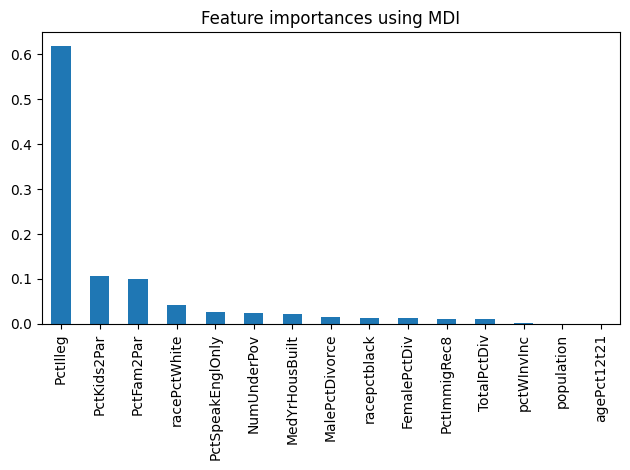

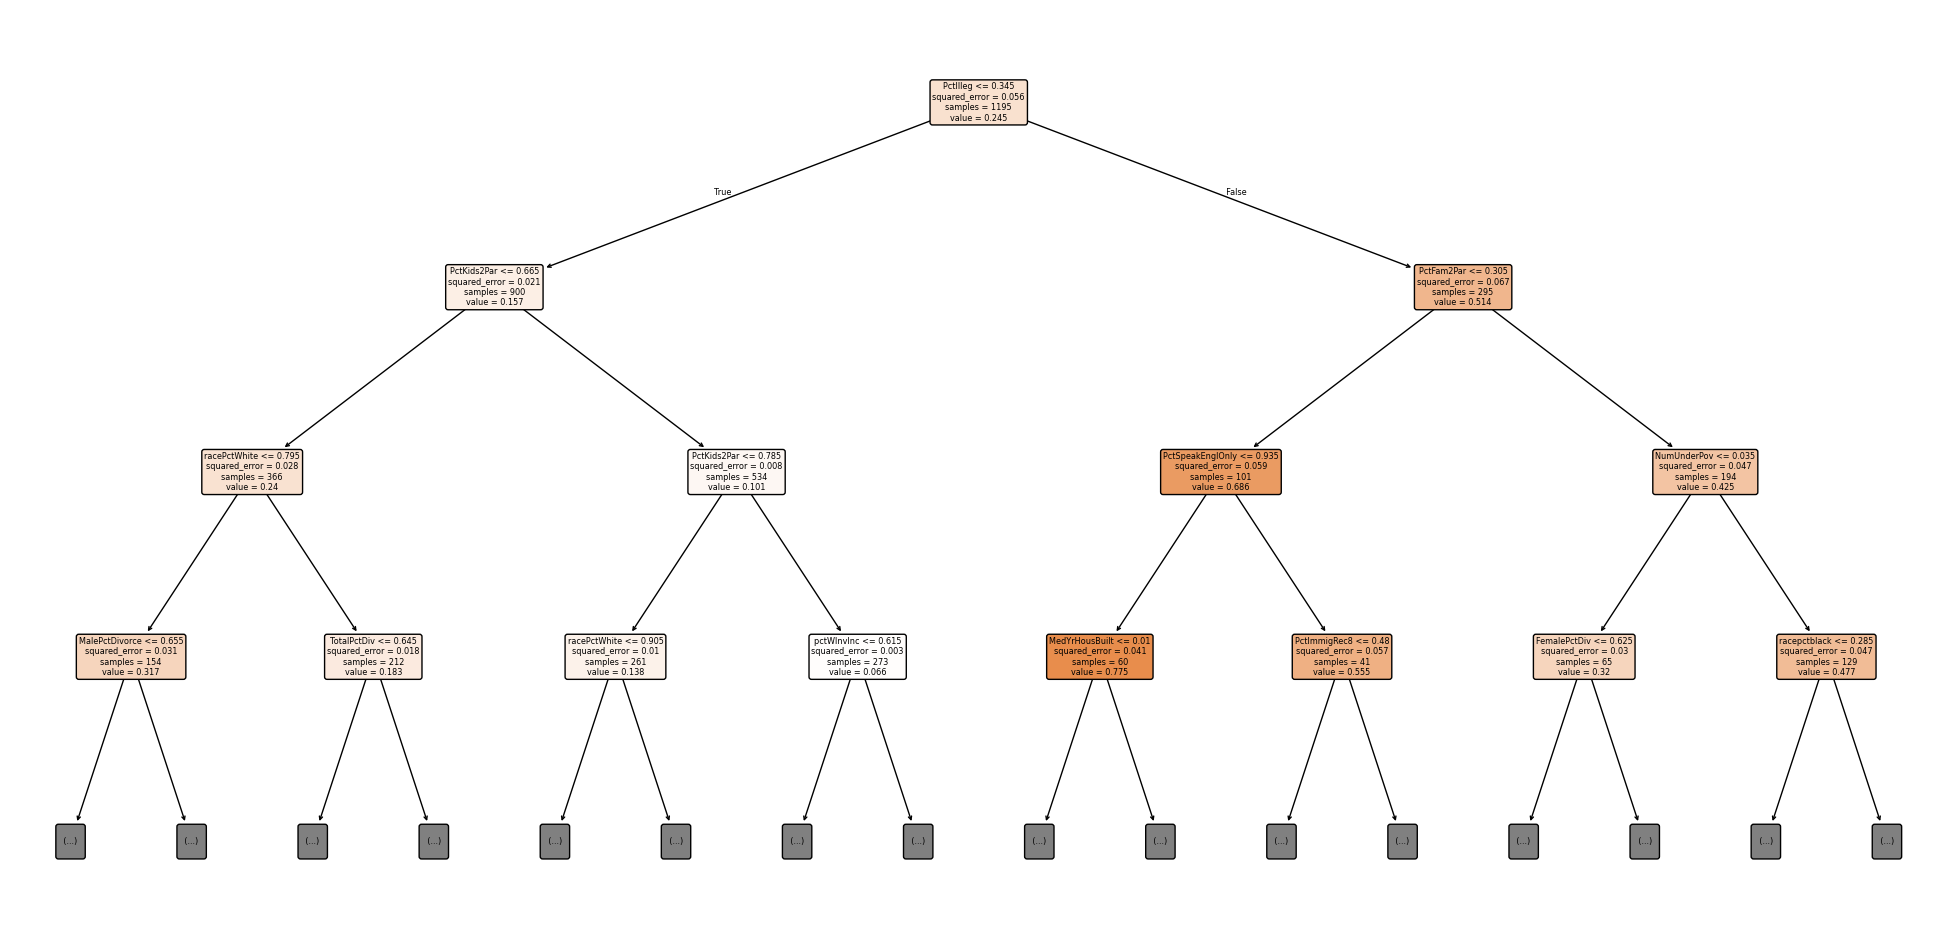

In [ ]:
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.model_selection import GridSearchCV
import pandas as pd
import matplotlib.pyplot as plt

# 1. Find the best hyperparameters using cross-validation on X_train
final_search = GridSearchCV(
    DecisionTreeRegressor(random_state=0),
    param_grid={
        "max_depth": [2, 3, 4, 5, 6, 8, 10, 12, 15, None],
        "min_samples_split": [2, 5, 10, 20],
        "min_samples_leaf": [1, 2, 5, 10]
    },
    scoring="neg_root_mean_squared_error",
    cv=5
)

final_search.fit(X_train, y_train)

# 2. Fit the final tree with the best parameters
final_model = final_search.best_estimator_

print("Best parameters:", final_search.best_params_)

# 3. Feature importances (top 15)
importance = pd.Series(
    final_model.feature_importances_,
    index=X_train.columns
)

importance.sort_values(ascending=False).head(15).plot.bar()
plt.title("Feature importances using MDI")
plt.tight_layout()
plt.show()

# 4. Plot the final decision tree
fig = plt.figure(figsize=(25, 12))

plot_tree(
    final_model,
    feature_names=X_train.columns,
    rounded=True,
    filled=True,
    max_depth=3
)

plt.show()

In [ ]:
import pandas as pd

comparison = pd.DataFrame([
    {
        "Model": "OLS",
        "RMSE mean": cv_results.loc["OLS", "RMSE mean"],
        "RMSE std": cv_results.loc["OLS", "RMSE std"],
        "MAE mean": cv_results.loc["OLS", "MAE mean"],
        "MAE std": cv_results.loc["OLS", "MAE std"],
        "R2 mean": cv_results.loc["OLS", "R2 mean"],
        "R2 std": cv_results.loc["OLS", "R2 std"]
    },
    {
        "Model": "Decision Tree",
        "RMSE mean": -tree_scores["test_RMSE"].mean(),
        "RMSE std": tree_scores["test_RMSE"].std(),
        "MAE mean": -tree_scores["test_MAE"].mean(),
        "MAE std": tree_scores["test_MAE"].std(),
        "R2 mean": tree_scores["test_R2"].mean(),
        "R2 std": tree_scores["test_R2"].std()
    }
])

comparison = comparison.set_index("Model").round(4)

print("Cross-validation comparison:")
display(comparison)

Cross-validation comparison:


,RMSE mean,RMSE std,MAE mean,MAE std,R2 mean,R2 std
Model,,,,,,
OLS,0.1426,0.0076,0.1019,0.0087,0.6228,0.0714
Decision Tree,0.1626,0.0048,0.1137,0.0028,0.5152,0.0445


We choose to keep the simple linear regression because it has the best performance in all metric for our first model.

# Second Model

## Random Forest

Meilleurs paramètres : {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 3, 'n_estimators': 243}
RMSE CV (train) : 0.13860589764812334
RMSE : 0.13848038982024174
MAE  : 0.09103232279909948
R²   : 0.6386284191435949


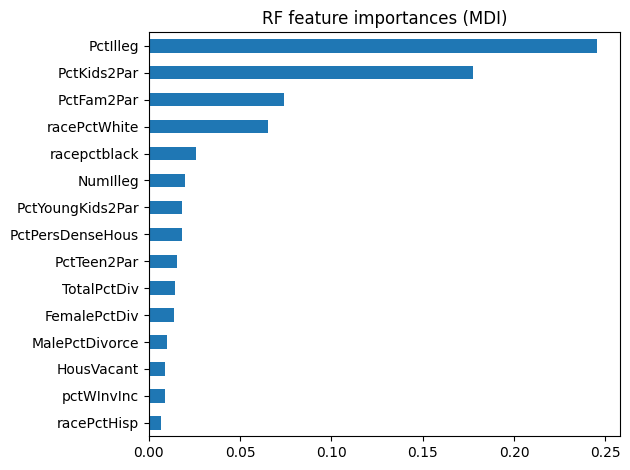

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

param_dist_rf = {
    'n_estimators': randint(200, 600),
    'max_depth': [None, 6, 10, 15, 20],
    'min_samples_leaf': randint(1, 10),
    'max_features': ['sqrt', 0.3, 0.5, 1.0],
}

rf_search = RandomizedSearchCV(
    RandomForestRegressor(random_state=0, n_jobs=-1),
    param_distributions=param_dist_rf,
    n_iter=30, cv=5,
    scoring='neg_root_mean_squared_error',
    random_state=0, n_jobs=-1)
rf_search.fit(X_train, y_train)

rf = rf_search.best_estimator_
print("Meilleurs paramètres :", rf_search.best_params_)
print("RMSE CV (train) :", -rf_search.best_score_)

y_pred_rf = rf.predict(X_test)
print("RMSE :", np.sqrt(mean_squared_error(y_test, y_pred_rf)))
print("MAE  :", mean_absolute_error(y_test, y_pred_rf))
print("R²   :", r2_score(y_test, y_pred_rf))

# Importance des variables
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(15)
imp[::-1].plot.barh(); plt.title("RF feature importances (MDI)"); plt.tight_layout(); plt.show()

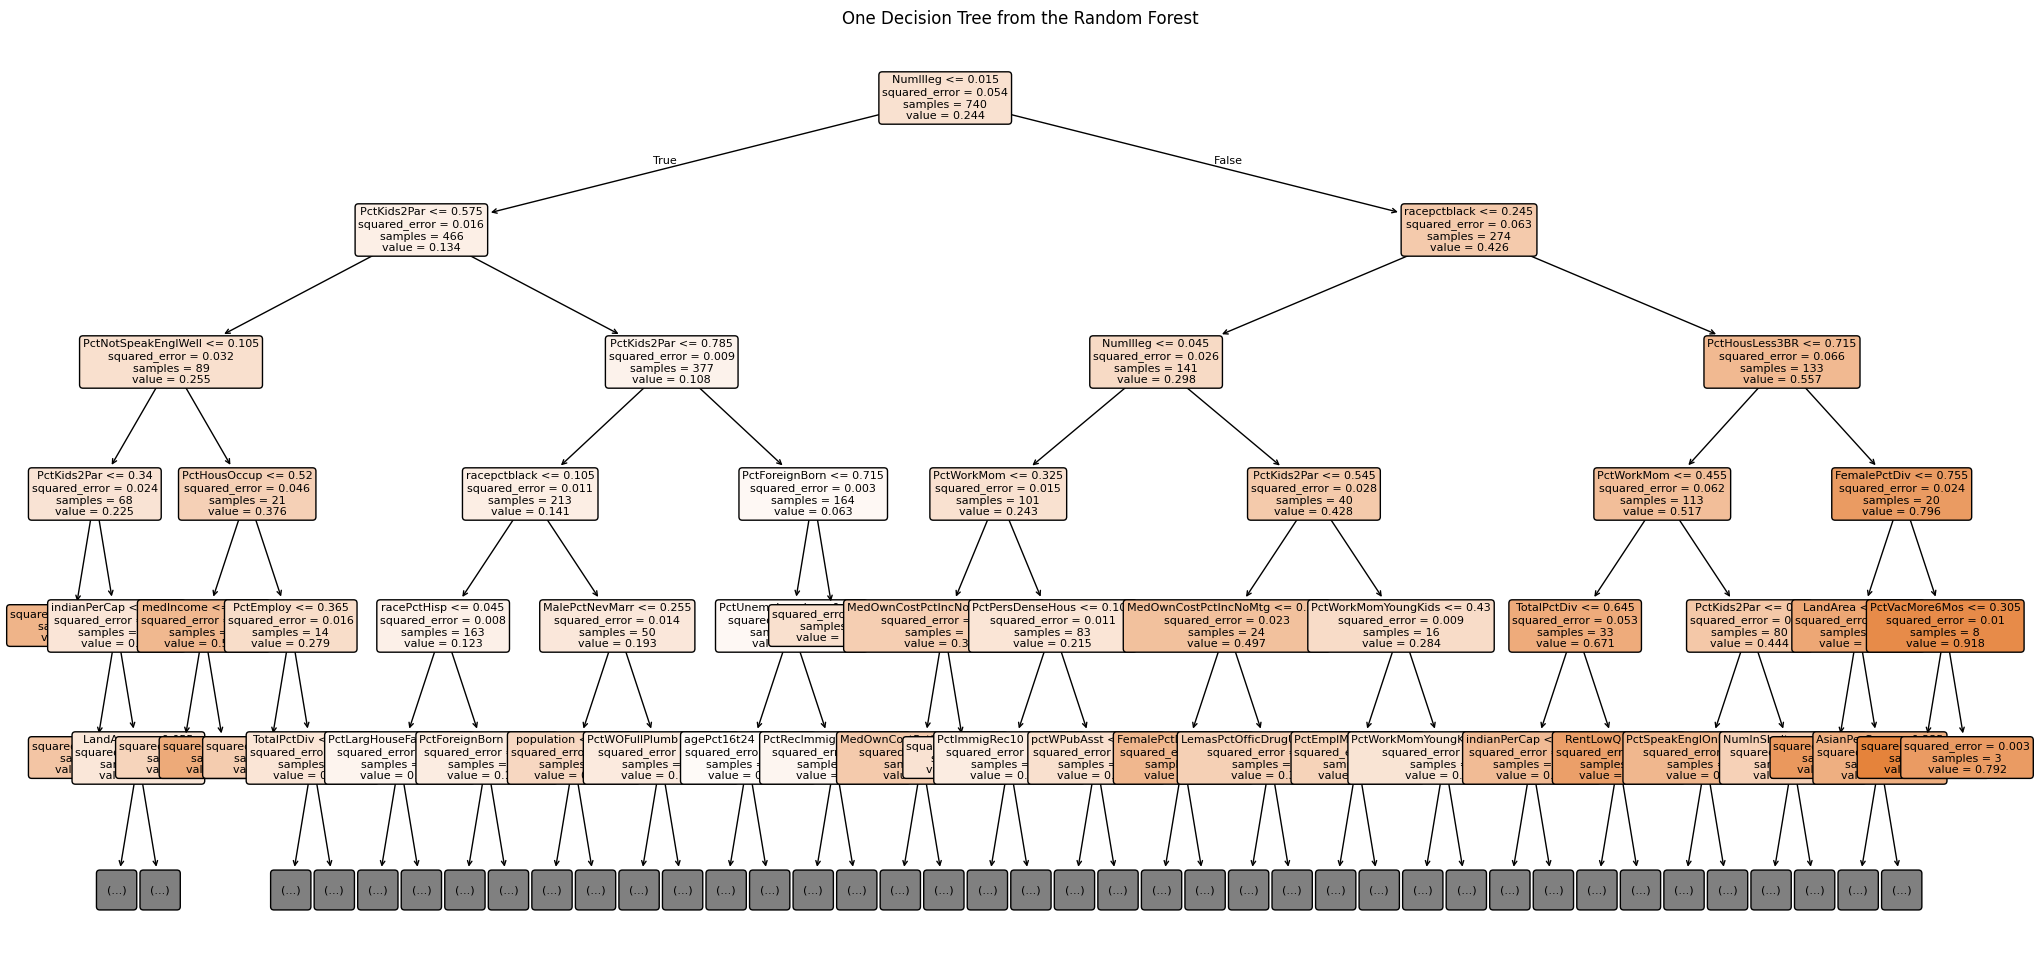

In [ ]:
#visualise the plot
from sklearn import tree
import matplotlib.pyplot as plt

# Select one tree from the Random Forest
one_tree = rf.estimators_[0]

# Visualise its first 5 levels
plt.figure(figsize=(25, 12))

tree.plot_tree(
    one_tree,
    feature_names=X_train.columns,
    filled=True,
    rounded=True,
    max_depth=5,
    fontsize=8
)

plt.title("One Decision Tree from the Random Forest")
plt.show()


In [ ]:
best_rf_params = rf_search.best_params_
print(best_rf_params)

rf_final = RandomForestRegressor(**best_rf_params, random_state=0, n_jobs=-1)

{'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 3, 'n_estimators': 243}


## Neural Network

Before modeling we try different kind of configuration to see which one is the most optimal and what kind of hyperparameter we should choose

#### Test

In [ ]:
import keras
from keras import Input
from keras.models import Sequential
from sklearn.preprocessing import StandardScaler
from keras.layers import Dense, Dropout
from keras.callbacks import EarlyStopping

# Standardiser les variables (fit sur le train uniquement)
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

# Structure du réseau
model = Sequential()
model.add(Input(shape=(X_train.shape[1],)))
model.add(Dense(64, activation='relu'))
model.add(Dense(32, activation='relu'))
model.add(Dense(1, activation='linear'))   # 1 seule sortie

model.summary()

# Hyperparamètres
model.compile(loss='mse', optimizer='adam', metrics=['mae'])

# Entraînement
model.fit(X_train_s, y_train, epochs=100, batch_size=32, verbose=1, validation_split=0.2)

# Test
y_pred_nn = model.predict(X_test_s).ravel()
print("RMSE :", np.sqrt(mean_squared_error(y_test, y_pred_nn)))
print("MAE  :", mean_absolute_error(y_test, y_pred_nn))
print("R²   :", r2_score(y_test, y_pred_nn))

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         6,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,577 (33.50 KB)

 Trainable params: 8,577 (33.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.2886 - mae: 0.3979 - val_loss: 0.0814 - val_mae: 0.2262
Epoch 2/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0771 - mae: 0.2106 - val_loss: 0.0604 - val_mae: 0.1896
Epoch 3/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0498 - mae: 0.1706 - val_loss: 0.0522 - val_mae: 0.1768
Epoch 4/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0382 - mae: 0.1490 - val_loss: 0.0495 - val_mae: 0.1726
Epoch 5/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0292 - mae: 0.1311 - val_loss: 0.0455 - val_mae: 0.1658
Epoch 6/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0246 - mae: 0.1216 - val_loss: 0.0434 - val_mae: 0.1622
Epoch 7/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0205 - mae: 0.1096 - val_loss: 0.0433 - val_mae: 0.1613
Epoch 8/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0181 - mae: 0.1036 - val_loss: 0.0421 - val_mae: 0.1590
Epoch 9/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.01

I ran a first NN with random hyperparameters and with 2 Density couch just to see the metrics

In [ ]:
def essayer(couches):
    m = Sequential()
    m.add(Input(shape=(X_train.shape[1],)))
    for n in couches:
        m.add(Dense(n, activation='relu'))
    m.add(Dense(1, activation='linear'))
    m.compile(loss='mse', optimizer='adam', metrics=['mae'])
    h = m.fit(X_train_s, y_train, epochs=100, batch_size=32,
              validation_split=0.2, verbose=0)
    return min(h.history['val_loss'])

for couches in [(16,), (32,), (64,), (64, 32), (128, 64)]:
    print(couches, "→ val_loss :", round(essayer(couches), 4))

(16,) → val_loss : 0.0358
(32,) → val_loss : 0.0383
(64,) → val_loss : 0.0498
(64, 32) → val_loss : 0.0344
(128, 64) → val_loss : 0.0274


here i tried to see how many couches is optimal => the last one is the best but since i plafonned it to this i try after to see if after the last one there is still a better couch distribution or not

In [ ]:
keras.utils.set_random_seed(0)

for couches in [(128, 64), (256, 128), (256, 128, 64), (512, 256), (128, 64, 32)]:
    scores = []
    for seed in range(3):                      # 3 essais pour lisser le hasard
        keras.utils.set_random_seed(seed)
        scores.append(essayer(couches))
    print(couches, "→ val_loss moyenne :", round(np.mean(scores), 4),
          "| écart-type :", round(np.std(scores), 4))

(128, 64) → val_loss moyenne : 0.0256 | écart-type : 0.0018
(256, 128) → val_loss moyenne : 0.0236 | écart-type : 0.0008
(256, 128, 64) → val_loss moyenne : 0.0212 | écart-type : 0.0004
(512, 256) → val_loss moyenne : 0.0214 | écart-type : 0.0005
(128, 64, 32) → val_loss moyenne : 0.023 | écart-type : 0.0019


the best one is (256, 128, 64) so we need to do a 3 couch NN with those parameters

I try to see concerning the dropout hyperparameters which one is the optimal option here :

In [ ]:
def tester(dropout, patience=15, seed=0):
    keras.utils.set_random_seed(seed)
    m = Sequential()
    m.add(Input(shape=(X_train.shape[1],)))
    for n in (256, 128, 64):
        m.add(Dense(n, activation='relu'))
        m.add(Dropout(dropout))
    m.add(Dense(1, activation='linear'))
    m.compile(loss='mse', optimizer='adam')
    es = EarlyStopping(monitor='val_loss', patience=patience, restore_best_weights=True)
    h = m.fit(X_train_s, y_train, epochs=200, batch_size=32,
              validation_split=0.2, callbacks=[es], verbose=0)
    return min(h.history['val_loss'])

for d in [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]:
    s = [tester(d, seed=k) for k in range(3)]
    print("dropout", d, "→", round(np.mean(s), 4), "±", round(np.std(s), 4))

dropout 0.0 → 0.0232 ± 0.0017
dropout 0.1 → 0.0205 ± 0.0004
dropout 0.2 → 0.0214 ± 0.0017
dropout 0.3 → 0.0215 ± 0.0006
dropout 0.4 → 0.0216 ± 0.0006
dropout 0.5 → 0.0221 ± 0.0008


0.1 is the best one so we choose also this one

In [ ]:
def tester2(patience, batch_size, seed=0):
    keras.utils.set_random_seed(seed)
    m = Sequential()
    m.add(Input(shape=(X_train.shape[1],)))
    for n in (256, 128, 64):
        m.add(Dense(n, activation='relu'))
        m.add(Dropout(0.1))
    m.add(Dense(1, activation='linear'))
    m.compile(loss='mse', optimizer='adam')
    es = EarlyStopping(monitor='val_loss', patience=patience, restore_best_weights=True)
    h = m.fit(X_train_s, y_train, epochs=200, batch_size=batch_size,
              validation_split=0.2, callbacks=[es], verbose=0)
    return min(h.history['val_loss'])

for p in [5, 15, 30]:
    for b in [16, 32, 64]:
        s = [tester2(p, b, seed=k) for k in range(3)]
        print("patience", p, "batch", b, "→", round(np.mean(s), 4), "±", round(np.std(s), 4))

patience 5 batch 16 → 0.0212 ± 0.0006
patience 5 batch 32 → 0.0219 ± 0.0014
patience 5 batch 64 → 0.0218 ± 0.0016
patience 15 batch 16 → 0.0209 ± 0.0009
patience 15 batch 32 → 0.0205 ± 0.0004
patience 15 batch 64 → 0.0217 ± 0.0016
patience 30 batch 16 → 0.0209 ± 0.001
patience 30 batch 32 → 0.0205 ± 0.0004
patience 30 batch 64 → 0.0209 ± 0.0015


The best combinations are patience 15 or 30 with batch 32, for the rest of the parameters i choose to not touch it because it's either not valuable for us or because it's recommended to keep the default option

## Modele Final

In [ ]:
# Modele Final
from keras.layers import Dropout
from keras.callbacks import EarlyStopping

keras.utils.set_random_seed(0)

model = Sequential()
model.add(Input(shape=(X_train.shape[1],)))
model.add(Dense(256, activation='relu'))
model.add(Dropout(0.1))      # 0.3 → 0.1
model.add(Dense(128, activation='relu'))
model.add(Dropout(0.1))      # 0.3 → 0.1
model.add(Dense(64, activation='relu'))
model.add(Dropout(0.1))      # 0.3 → 0.1
model.add(Dense(1, activation='linear'))
model.compile(loss='mse', optimizer='adam', metrics=['mae'])

es = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)
history = model.fit(X_train_s, y_train, epochs=200, batch_size=32,
                    validation_split=0.2, callbacks=[es], verbose=0)

y_pred_nn = model.predict(X_test_s).ravel()
print("Epochs :", len(history.history['loss']))
print("RMSE :", np.sqrt(mean_squared_error(y_test, y_pred_nn)))
print("MAE  :", mean_absolute_error(y_test, y_pred_nn))
print("R²   :", r2_score(y_test, y_pred_nn))

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
Epochs : 28
RMSE : 0.14478384451272783
MAE  : 0.09705330391276748
R²   : 0.6049813051722778


### Tab Comparison

In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

predictions = {
    'Linear Regression': y_pred_lr,
    'Decision Tree':     y_pred_tree,
    'Random Forest':     y_pred_rf,
    'Neural Network':    y_pred_nn,
}

results = pd.DataFrame({
    'Model': list(predictions.keys()),
    'RMSE': [np.sqrt(mean_squared_error(y_test, p)) for p in predictions.values()],
    'MAE':  [mean_absolute_error(y_test, p) for p in predictions.values()],
    'R²':   [r2_score(y_test, p) for p in predictions.values()],
}).round(4)

print(results.to_string(index=False))

            Model   RMSE    MAE     R²
Linear Regression 0.1389 0.0956 0.6364
    Decision Tree 0.1586 0.1097 0.5258
    Random Forest 0.1385 0.0910 0.6386
   Neural Network 0.1448 0.0971 0.6050


# Conformal Prediction — Linear Regression and Random Forest

The objective is to estimate **90% prediction intervals** for the normalized violent crime rate. Two regression models (Linear Regression and Random Forest) are evaluated using two conformal methods (Split CP and CV+), giving four combinations.

The analysis uses the established **training, calibration and test sets**, the fitted Linear Regression and the Random Forest selected by `RandomizedSearchCV`. Model tuning used 5-fold cross-validation; **10 folds** are used here for CV+. The test set remains excluded from fitting and calibration.


In [ ]:
# Imports and validation of the existing data and fitted models
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.utils.validation import check_is_fitted

required_names = (
    "X_train", "X_calib", "X_trval", "X_test",
    "y_train", "y_calib", "y_trval", "y_test", "lr", "rf_search"
)
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise RuntimeError(
        "Run the existing data-preparation, Linear Regression and Random Forest tuning cells first. "
        f"Missing: {missing_names}"
    )

cp_lr = lr
cp_rf = rf_search.best_estimator_
check_is_fitted(cp_lr)
check_is_fitted(cp_rf)

alpha = 0.10
nominal_coverage = 1 - alpha
n_cv_folds = 10

cp_y_train = np.asarray(y_train, dtype=float).ravel()
cp_y_calib = np.asarray(y_calib, dtype=float).ravel()
cp_y_trval = np.asarray(y_trval, dtype=float).ravel()
cp_y_test = np.asarray(y_test, dtype=float).ravel()

for X_part, y_part, label in (
    (X_train, cp_y_train, "Training"),
    (X_calib, cp_y_calib, "Calibration"),
    (X_trval, cp_y_trval, "Development"),
    (X_test, cp_y_test, "Test"),
):
    if len(X_part) != len(y_part):
        raise ValueError(f"{label} X and y have different lengths.")
    if not np.all(np.isfinite(y_part)):
        raise ValueError(f"{label} targets contain missing or infinite values.")

if len(X_trval) != len(X_train) + len(X_calib):
    raise ValueError("Development data must contain training and calibration observations.")

if all(hasattr(obj, "columns") for obj in (X_train, X_calib, X_trval, X_test)):
    columns = list(X_train.columns)
    if any(list(obj.columns) != columns for obj in (X_calib, X_trval, X_test)):
        raise ValueError("All four feature matrices must have identical column order.")

if all(hasattr(obj, "index") for obj in (X_train, X_calib, X_trval, X_test)):
    if not (set(X_train.index).isdisjoint(X_calib.index)
            and set(X_train.index).isdisjoint(X_test.index)
            and set(X_calib.index).isdisjoint(X_test.index)):
        raise ValueError("Train, calibration and test sets must be disjoint.")

print(f"Training: {len(X_train)} | Calibration: {len(X_calib)} | Test: {len(X_test)}")
print(f"CV+ development sample: {len(X_trval)} observations")
print(f"Nominal coverage: {nominal_coverage:.0%}")
print("Random Forest selected hyperparameters:", rf_search.best_params_)


Training: 1195 | Calibration: 399 | Test: 399
CV+ development sample: 1594 observations
Nominal coverage: 90%
Random Forest selected hyperparameters: {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 3, 'n_estimators': 243}


## 1. Split conformal prediction

Each model is fitted on the training set. On the separate calibration set, prediction errors are measured as absolute residuals: \(s_i = |y_i - \hat{y}_i|\). The corrected 90th percentile of these errors is \(\hat{q}\). For a new observation, the interval is \([\hat{y}-\hat{q},\ \hat{y}+\hat{q}]\).

The **same calibration and test observations** are used for both models. Split CP produces constant-width intervals for each fitted model.


In [ ]:
# Split CP: use the existing fitted estimators; no new model tuning

def split_cp(fitted_model, X_calibration, y_calibration, X_new, alpha=0.10):
    y_calibration = np.asarray(y_calibration, dtype=float).ravel()
    calibration_prediction = np.asarray(
        fitted_model.predict(X_calibration), dtype=float
    ).ravel()
    scores = np.abs(y_calibration - calibration_prediction)
    n = len(scores)

    # Finite-sample corrected quantile: rank ceil((n+1)*(1-alpha))
    rank = int(np.ceil((n + 1) * (1 - alpha)))
    if not 1 <= rank <= n:
        raise ValueError("Insufficient calibration observations for the target coverage.")
    q_hat = float(np.partition(scores, rank - 1)[rank - 1])

    prediction = np.asarray(fitted_model.predict(X_new), dtype=float).ravel()
    return {
        "pred": prediction,
        "lo": prediction - q_hat,
        "hi": prediction + q_hat,
        "q_hat": q_hat,
        "calibration_scores": scores,
    }

cp_results = {}
cp_results[("Linear Regression", "Split CP")] = split_cp(
    cp_lr, X_calib, cp_y_calib, X_test, alpha
)
cp_results[("Random Forest", "Split CP")] = split_cp(
    cp_rf, X_calib, cp_y_calib, X_test, alpha
)

for model_label in ("Linear Regression", "Random Forest"):
    split_result = cp_results[(model_label, "Split CP")]
    print(f"{model_label}: q_hat = {split_result['q_hat']:.4f}; "
          f"interval width = {2 * split_result['q_hat']:.4f}")


Linear Regression: q_hat = 0.2045; interval width = 0.4091
Random Forest: q_hat = 0.2080; interval width = 0.4159


## 2. Cross-validation+ (CV+, 10 folds)

The training and calibration observations are combined into the **development sample** (`X_trval`). In each of 10 folds, a model is fitted on nine folds and predicts the held-out fold. The absolute out-of-fold errors and the corresponding fold-model predictions are then used to construct the test intervals.

The Random Forest is refitted in every fold with the **same hyperparameters selected earlier**. Hyperparameters are not searched again. CV+ uses more fitting operations than Split CP but does not require a separate calibration subset.


In [ ]:
# CV+ with 10 folds: out-of-fold errors and fold-specific predictions

def cp_take_rows(matrix, row_ids):
    return matrix.iloc[row_ids] if hasattr(matrix, "iloc") else np.asarray(matrix)[row_ids]


def cv_plus(base_estimator, X_development, y_development, X_new,
            alpha=0.10, n_splits=10):
    y_development = np.asarray(y_development, dtype=float).ravel()
    n = len(y_development)
    n_new = len(X_new)
    if not 2 <= n_splits <= n:
        raise ValueError("The number of folds must be between 2 and the sample size.")

    lower_candidates = np.empty((n, n_new), dtype=float)
    upper_candidates = np.empty((n, n_new), dtype=float)
    out_of_fold_errors = np.empty(n, dtype=float)
    fold_predictions = []

    folds = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    for fold_number, (fit_idx, holdout_idx) in enumerate(
        folds.split(X_development), start=1
    ):
        fold_model = clone(base_estimator)
        fold_model.fit(cp_take_rows(X_development, fit_idx), y_development[fit_idx])

        holdout_prediction = np.asarray(
            fold_model.predict(cp_take_rows(X_development, holdout_idx)),
            dtype=float
        ).ravel()
        errors = np.abs(y_development[holdout_idx] - holdout_prediction)
        new_prediction = np.asarray(fold_model.predict(X_new), dtype=float).ravel()

        out_of_fold_errors[holdout_idx] = errors
        lower_candidates[holdout_idx, :] = new_prediction[None, :] - errors[:, None]
        upper_candidates[holdout_idx, :] = new_prediction[None, :] + errors[:, None]
        fold_predictions.append(new_prediction)
        print(f"  Fold {fold_number}/{n_splits}")

    # Finite-sample CV+ lower and upper order statistics
    lower_rank = max(1, int(np.floor((n + 1) * alpha)))
    upper_rank = min(n, int(np.ceil((n + 1) * (1 - alpha))))
    lower = np.partition(lower_candidates, lower_rank - 1, axis=0)[lower_rank - 1]
    upper = np.partition(upper_candidates, upper_rank - 1, axis=0)[upper_rank - 1]
    point_prediction = np.mean(fold_predictions, axis=0)

    return {
        "pred": point_prediction,
        "lo": lower,
        "hi": upper,
        "oof_residuals": out_of_fold_errors,
    }

print("Linear Regression + CV+:")
cp_results[("Linear Regression", "CV+ (10 folds)")] = cv_plus(
    cp_lr, X_trval, cp_y_trval, X_test, alpha, n_cv_folds
)

print("Random Forest + CV+:")
cp_results[("Random Forest", "CV+ (10 folds)")] = cv_plus(
    cp_rf, X_trval, cp_y_trval, X_test, alpha, n_cv_folds
)


Linear Regression + CV+:
  Fold 1/10
  Fold 2/10
  Fold 3/10
  Fold 4/10
  Fold 5/10
  Fold 6/10
  Fold 7/10
  Fold 8/10
  Fold 9/10
  Fold 10/10
Random Forest + CV+:
  Fold 1/10
  Fold 2/10
  Fold 3/10
  Fold 4/10
  Fold 5/10
  Fold 6/10
  Fold 7/10
  Fold 8/10
  Fold 9/10
  Fold 10/10


## 3. Coverage, interval width and predictive accuracy

**Regression Coverage Score (RCS)** is the proportion of actual test values inside the intervals. It is compared with the 90% nominal level. **Regression Mean Width Score (RMWS)** is the average interval width; narrower intervals are preferable when coverage is comparable. **RMSE, MAE and R²** describe the accuracy of the corresponding point predictions.

All four methods are evaluated on **the same test set**. Interval bounds are not clipped to [0, 1], so the width comparison uses the intervals as constructed.


In [ ]:
# Final comparison: two regression models × two conformal methods
combinations = [
    ("Linear Regression", "Split CP"),
    ("Linear Regression", "CV+ (10 folds)"),
    ("Random Forest", "Split CP"),
    ("Random Forest", "CV+ (10 folds)"),
]

cp_rows = []
for model_label, method_label in combinations:
    record = cp_results[(model_label, method_label)]
    prediction = np.asarray(record["pred"], dtype=float).ravel()
    lower = np.asarray(record["lo"], dtype=float).ravel()
    upper = np.asarray(record["hi"], dtype=float).ravel()

    if not (len(prediction) == len(lower) == len(upper) == len(cp_y_test)):
        raise ValueError(f"Test output lengths do not match: {model_label}, {method_label}")
    if not all(np.all(np.isfinite(arr)) for arr in (prediction, lower, upper)):
        raise ValueError(f"Non-finite predictions or bounds: {model_label}, {method_label}")
    if np.any(lower > upper):
        raise ValueError(f"Invalid interval bounds: {model_label}, {method_label}")

    inside = (lower <= cp_y_test) & (cp_y_test <= upper)
    rcs = float(np.mean(inside))
    rmws = float(np.mean(upper - lower))
    cp_rows.append({
        "Model": model_label,
        "Method": method_label,
        "RMSE": np.sqrt(mean_squared_error(cp_y_test, prediction)),
        "MAE": mean_absolute_error(cp_y_test, prediction),
        "R²": r2_score(cp_y_test, prediction),
        "RCS": rcs,
        "Covered": f"{int(inside.sum())}/{len(cp_y_test)}",
        "RMWS": rmws,
        "Gap vs 90% (pp)": 100 * (rcs - nominal_coverage),
    })

cp_table = pd.DataFrame(cp_rows)
print("CONFORMAL PREDICTION — TEST RESULTS")
print(cp_table.round(4).to_string(index=False))


CONFORMAL PREDICTION — TEST RESULTS
            Model         Method   RMSE    MAE     R²    RCS Covered   RMWS  Gap vs 90% (pp)
Linear Regression       Split CP 0.1389 0.0956 0.6364 0.8972 358/399 0.4091          -0.2757
Linear Regression CV+ (10 folds) 0.1385 0.0948 0.6383 0.9098 363/399 0.4487           0.9774
    Random Forest       Split CP 0.1385 0.0910 0.6386 0.9048 361/399 0.4159           0.4762
    Random Forest CV+ (10 folds) 0.1388 0.0914 0.6367 0.9023 360/399 0.4409           0.2256


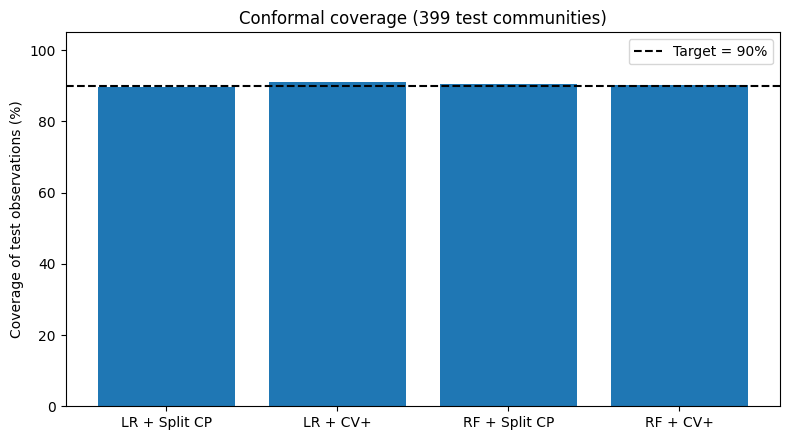

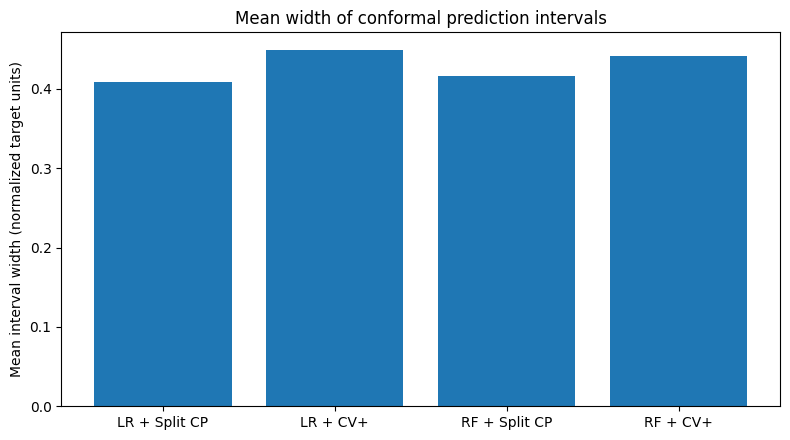

In [ ]:
# Empirical coverage and average interval width for the four combinations
comparison_labels = [
    f"{'LR' if model == 'Linear Regression' else 'RF'} + "
    f"{'Split CP' if method == 'Split CP' else 'CV+'}"
    for model, method in zip(cp_table["Model"], cp_table["Method"])
]

plt.figure(figsize=(8, 4.5))
plt.bar(comparison_labels, cp_table["RCS"] * 100)
plt.axhline(90, color="black", linestyle="--", label="Target = 90%")
plt.ylim(0, 105)
plt.ylabel("Coverage of test observations (%)")
plt.title(f"Conformal coverage ({len(cp_y_test)} test communities)")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4.5))
plt.bar(comparison_labels, cp_table["RMWS"])
plt.ylabel("Mean interval width (normalized target units)")
plt.title("Mean width of conformal prediction intervals")
plt.tight_layout()
plt.show()


## 4. Coverage by predicted crime level

A single average coverage rate can hide differences between low- and high-crime predictions. The test sample is divided into **five groups using the same Random Forest predictions** for all four methods (Q1: lowest predicted crime; Q5: highest). Coverage is calculated separately for each group.


COVERAGE BY PREDICTED CRIME GROUP (Q1 lowest, Q5 highest)
            Model         Method    Q1    Q2    Q3    Q4    Q5
Linear Regression       Split CP 0.988 0.950 0.962 0.888 0.700
Linear Regression CV+ (10 folds) 0.988 0.975 0.962 0.900 0.725
    Random Forest       Split CP 0.988 0.975 0.937 0.912 0.712
    Random Forest CV+ (10 folds) 0.988 0.975 0.937 0.925 0.688


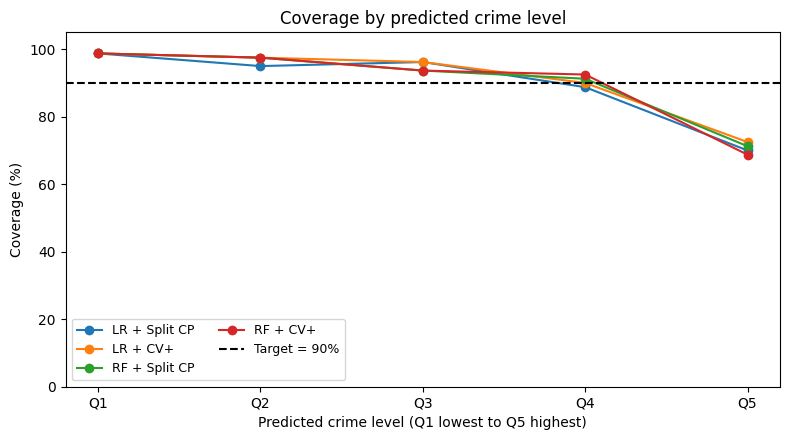

In [ ]:
# Conditional check: coverage across identical predicted-crime groups
reference_prediction = np.asarray(cp_rf.predict(X_test), dtype=float).ravel()
quintile = np.asarray(
    pd.qcut(reference_prediction, q=5, labels=False, duplicates="drop"),
    dtype=int
)

cp_group_rows = []
for model_label, method_label in combinations:
    record = cp_results[(model_label, method_label)]
    inside = ((np.asarray(record["lo"], dtype=float) <= cp_y_test)
              & (cp_y_test <= np.asarray(record["hi"], dtype=float)))
    row = {"Model": model_label, "Method": method_label}
    for group in sorted(np.unique(quintile)):
        row[f"Q{group + 1}"] = float(np.mean(inside[quintile == group]))
    cp_group_rows.append(row)

cp_group_table = pd.DataFrame(cp_group_rows)
print("COVERAGE BY PREDICTED CRIME GROUP (Q1 lowest, Q5 highest)")
print(cp_group_table.round(3).to_string(index=False))

quintile_columns = [col for col in cp_group_table if col.startswith("Q")]
plt.figure(figsize=(8, 4.5))
for _, row in cp_group_table.iterrows():
    label = "LR" if row["Model"] == "Linear Regression" else "RF"
    label += " + Split CP" if row["Method"] == "Split CP" else " + CV+"
    plt.plot(quintile_columns, row[quintile_columns].to_numpy(dtype=float) * 100,
             marker="o", label=label)
plt.axhline(90, color="black", linestyle="--", label="Target = 90%")
plt.ylim(0, 105)
plt.xlabel("Predicted crime level (Q1 lowest to Q5 highest)")
plt.ylabel("Coverage (%)")
plt.title("Coverage by predicted crime level")
plt.legend(ncol=2, fontsize=9)
plt.tight_layout()
plt.show()


## 5. Results interpretation

The test comparison reports the number of observations covered by each method, the gap from 90% and the average interval width. A lower width is useful **only alongside sufficient coverage**. The final lines report coverage in the highest predicted-crime group to check whether the overall result holds for higher predicted values.

Split CP and CV+ use different training procedures, so their point-prediction RMSE may differ even with the same regression algorithm. The 90% coverage level is a **marginal target**, not a 90% coverage guarantee within each subgroup.


In [ ]:
# Numerical interpretation from the current test results
for model_label in ("Linear Regression", "Random Forest"):
    subset = cp_table[cp_table["Model"] == model_label].set_index("Method")
    split = subset.loc["Split CP"]
    cv = subset.loc["CV+ (10 folds)"]
    print(
        f"{model_label}: Split CP covers {split['Covered']} test observations "
        f"({split['RCS']:.1%}), mean width {split['RMWS']:.4f}; "
        f"CV+ covers {cv['Covered']} ({cv['RCS']:.1%}), "
        f"mean width {cv['RMWS']:.4f}. "
        f"CV+ width minus Split CP width: {cv['RMWS'] - split['RMWS']:+.4f}."
    )

highest_group = [col for col in cp_group_table if col.startswith("Q")][-1]
print(f"\nCoverage in the highest predicted-crime group ({highest_group}):")
for _, row in cp_group_table.iterrows():
    print(f"{row['Model']} + {row['Method']}: {row[highest_group]:.1%}")


Linear Regression: Split CP covers 358/399 test observations (89.7%), mean width 0.4091; CV+ covers 363/399 (91.0%), mean width 0.4487. CV+ width minus Split CP width: +0.0396.
Random Forest: Split CP covers 361/399 test observations (90.5%), mean width 0.4159; CV+ covers 360/399 (90.2%), mean width 0.4409. CV+ width minus Split CP width: +0.0250.

Coverage in the highest predicted-crime group (Q5):
Linear Regression + Split CP: 70.0%
Linear Regression + CV+ (10 folds): 72.5%
Random Forest + Split CP: 71.2%
Random Forest + CV+ (10 folds): 68.8%
